In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys

sys.path.insert(1,"../src/")

In [3]:
import numpy as np
import scipy.io
import matplotlib.pyplot as plt
import scipy.signal as sp
import scipy.stats as stats

import monte_carlo_modes as mcm

import acoustic_inversion as ai 

In [4]:
# [Title, Freq, ssp, bdry, pos, beam, cint, rmax] = at.read_env("feif_scenario.env", "KRAKEN")

In [5]:
SAMPLING_FREQ = 2000
TRUE_SOUNDSPEED = 1460
TRUE_DENSITY = 1.6

In [6]:
data1 = scipy.io.loadmat("../data/field_values20260707/field_values20260707.mat")


f = data1['f'].squeeze()
f_Vg = f[1:-1]
c = data1['soundspeed'].squeeze()
Vg = data1['Vg'].squeeze().transpose([1,0,2])
rho = data1['rho'].squeeze()
receiver_range = data1['range'][0,0]

In [7]:
Vg.shape

(29, 17, 299)

In [8]:
arrival_times_data = receiver_range/Vg[c == TRUE_SOUNDSPEED, ...].squeeze()
arrival_times_replica = receiver_range/Vg

In [9]:
lk = ai.AcousticInversionLikelihood(arrival_times_data)

In [10]:
likelihood = lk.likelihood(arrival_times_replica)

#likelihood = likelihood/likelihood.sum()

In [32]:
ntrials = 2000

selected = [np.arange(15)[np.random.binomial(1, .5, 15) ==1] for n in range(ntrials)]
perturb = np.random.randint(0, 3, ntrials)

mode_labels = [s +p for s,p in zip(selected, perturb)]

In [33]:
hasmode1 = np.array([np.any(s==0) for s in selected]) 
hasmode1correct = np.all([hasmode1, perturb==0], 0)

In [34]:
normalize01 = lambda x: x/x.sum()
var = lambda p,x: np.sum(p*(x**2)) - np.sum(p*x)**2

In [48]:
likelihood_mc = np.empty((ntrials, len(c)))
var_mc = np.empty(ntrials)
for trial in range(ntrials):
    atimes_data = arrival_times_data[selected[trial]]
    atimes_replica = arrival_times_replica[:, mode_labels[trial]]
    atimes_data = atimes_data + np.random.normal(size=atimes_data.shape)*.001
    lk_mc = ai.AcousticInversionLikelihood(atimes_data)
    likelihood_mc[trial] = normalize01(lk_mc.likelihood(atimes_replica))
    var_mc[trial] = var(likelihood_mc[trial], c)
    

In [49]:
means = likelihood_mc @ c
moment2 = likelihood_mc @ (c**2)
variance = moment2 - means**2

In [50]:
likelihood_mc

array([[0.03447539, 0.03447556, 0.03447588, ..., 0.03448043, 0.03447806,
        0.03447589],
       [0.03448694, 0.03448784, 0.03448794, ..., 0.03447449, 0.03447408,
        0.03447466],
       [0.03447876, 0.03448019, 0.03448136, ..., 0.03447729, 0.03447512,
        0.03447264],
       ...,
       [0.03448848, 0.03448879, 0.034489  , ..., 0.03447171, 0.03446874,
        0.03446548],
       [0.03448342, 0.03448344, 0.03448418, ..., 0.03447924, 0.03447876,
        0.03447833],
       [0.03449314, 0.03449252, 0.03449179, ..., 0.03447022, 0.03446898,
        0.03446781]], shape=(2000, 29))

In [51]:
var_unpert = variance[perturb == 0]
var_pert = variance[perturb != 0]

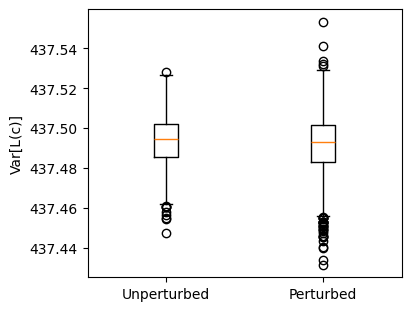

In [52]:
fig, ax = plt.subplots(layout="constrained")

ax.boxplot([var_unpert, var_pert])

ax.set_xticklabels(["Unperturbed", "Perturbed"])
ax.set_ylabel("Var[L(c)]")

fig.set_size_inches([4,3])

fig.savefig("../data/output/figures/lvariance_boxplot.png", dpi=600)

In [53]:
lk_unpert = normalize01(likelihood_mc[perturb == 0])
lk_pert = normalize01(likelihood_mc[perturb != 0])

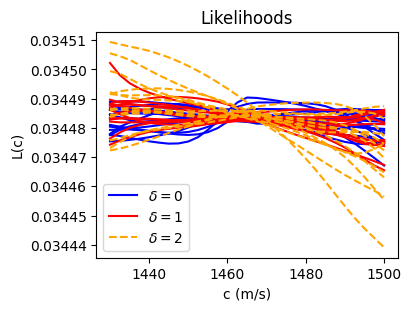

In [54]:
fig, ax = plt.subplots(layout="constrained")



l0 = ax.plot(c, likelihood_mc[perturb == 0][::50].T, 'b', label="$\\delta=0$")
l1 = ax.plot(c, likelihood_mc[perturb == 1][::50].T, 'r', label="$\\delta=1$")
l2 = ax.plot(c, likelihood_mc[perturb == 2][::50].T, '--', c='orange', label="$\\delta=2$")

ax.set_title("Likelihoods")
ax.set_xlabel("c (m/s)")
ax.set_ylabel("L(c)")

ax.legend([l0[0], l1[0], l2[0]], ["$\\delta=0$", "$\\delta=1$", "$\\delta=2$"])

fig.set_size_inches([4,3])

fig.savefig("../data/output/figures/perturbed_likelihoods.png", dpi=600)

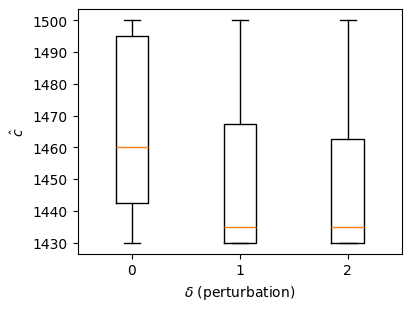

In [55]:
fig, ax = plt.subplots(layout="constrained")

ax.boxplot([
    c[np.argmax(likelihood_mc[perturb == 0], axis=1)],
    c[np.argmax(likelihood_mc[perturb == 1], axis=1)],
    c[np.argmax(likelihood_mc[perturb == 2], axis=1)]
])

ax.set_xlabel("$\\delta$ (perturbation)")

ax.set_ylabel("$\\hat{c}$")

ax.set_xticklabels([0,1,2])

fig.set_size_inches([4,3])

fig.savefig("../data/output/figures/mle_boxplot.png", dpi=600)


In [21]:
np.diff(np.array([1,2,3,5,6,8,9,12,13]))

array([1, 1, 2, 1, 2, 1, 3, 1])

In [16]:
rng = np.random.default_rng(50)

selected = mcm.select_modes(rng, 17, 1000)

In [17]:
splitted = mcm.split_clusters(selected)